In [ ]:
import pickle
import gzip
from datasets import load_dataset
from tqdm import tqdm

score_dict_file = "/home/ubuntu/opensearch-sparse-model-tuning-sample/.cache/cross-encoder-ms-marco-MiniLM-L-6-v2-scores.pkl.gz"

with gzip.open(score_dict_file, "rb") as f:
    scores_dict = pickle.load(f)

class MsmarcoAccessor:
    @staticmethod
    def transform_str(s):
        try:
            s = s.encode("latin1").decode("utf-8")
            return s
        except Exception:
            return s

    def _prepare_corpus(self):
        corpus = load_dataset("BeIR/msmarco", "corpus", split="corpus")
        if self.do_transform:
            corpus = corpus.map(
                lambda x: {"text": MsmarcoAccessor.transform_str(x["text"])},
                num_proc=30,
            )
        self.corpus = corpus["text"]

    def _prepare_qrels(self):
        qrels = load_dataset("BEIR/msmarco-qrels", split="train")
        self.qrels = {}
        for sample in tqdm(qrels):
            q_id = sample["query-id"]
            d_id = sample["corpus-id"]
            if q_id not in self.qrels:
                self.qrels[q_id] = []
            self.qrels[q_id].append(d_id)

    def _prepare_queries(self):
        queries = load_dataset("BeIR/msmarco", "queries", split="queries")
        self.queries = dict()
        for sample in tqdm(queries):
            self.queries[int(sample["_id"])] = sample["text"]

    def __init__(self, do_transform=True):
        self.do_transform = do_transform
        self._prepare_corpus()
        self._prepare_qrels()
        self._prepare_queries()

accessor = MsmarcoAccessor()

In [ ]:
with open("msmarco_all_q.pkl", "rb") as f:
    all_q = pickle.load(f)

with open("msmarco_all_d_list.pkl", "rb") as f:
    all_d_list = pickle.load(f)

In [31]:
from datasets import Dataset

data = {"query": [], "docs": []}
for q, d_list in zip(all_q, all_d_list):
    data["query"].append(accessor.queries[q])
    data["docs"].append([accessor.corpus[i] for i in d_list])

dataset = Dataset.from_dict(data)
dataset.save_to_disk("msmarco_st")


Saving the dataset (0/36 shards):   0%|          | 0/502822 [00:00<?, ? examples/s]

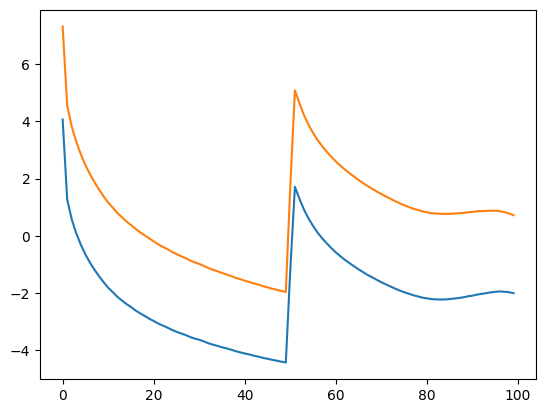

In [ ]:
from matplotlib import pyplot as plt
import numpy as np

# with open("msmarco_scores.pkl", "rb") as f:
#     scores = np.array(pickle.load(f))

scores_minilm = np.load("scores/msmarco_st/minilm-l6_scores.npy").astype(np.float32)
scores_t5 = np.load("scores/msmarco_st/t5_scores.npy").astype(np.float32)

plt.plot(scores_t5.mean(axis=0).reshape(-1))
plt.plot(scores_minilm.mean(axis=0).reshape(-1))
plt.show()


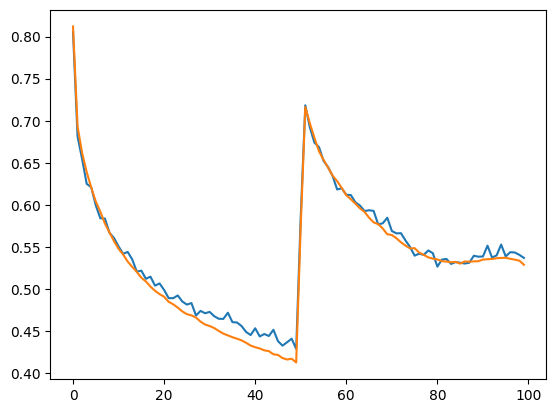

In [8]:
scores_minilm = (scores_minilm - scores_minilm.min(axis=0)) / (scores_minilm.max(axis=0) - scores_minilm.min(axis=0))
scores_t5 = (scores_t5 - scores_t5.min(axis=0)) / (scores_t5.max(axis=0) - scores_t5.min(axis=0))

scores = scores_minilm + scores_t5
scores /= 2

plt.plot(scores_t5.mean(axis=0).reshape(-1))
plt.plot(scores_minilm.mean(axis=0).reshape(-1))
plt.show()


In [9]:
with open("msmarco_scores.pkl", "rb") as f:
    target_scores = np.array(pickle.load(f))
print(target_scores.shape, target_scores.mean(), target_scores.var(), target_scores.min(), target_scores.max())
final_scores = (scores - scores.mean())*(target_scores.std()/scores.std()) + target_scores.mean()

(502822, 100) 0.8310783877590019 28.38879802989393 -11.544254302978516 11.673728942871094


In [ ]:
num = 0
new_scores_dict = {}
scores_list = scores_minilm.tolist()

for i in range(len(all_q)):
    q_id = all_q[i]
    d_id = all_d_list[i]
    score = scores_list[i]

    assert len(d_id) == 100
    assert len(score) == 100

    new_scores_dict[q_id] = {d_id[j]: score[j] for j in range(100)}

import gzip
import pickle

with gzip.open("minilm_t5_scores.pkl.gz", "wb", compresslevel=1) as f:
    pickle.dump(new_scores_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

(array([248837., 342749., 285170., 269511., 251401., 242030., 233669.,
        229424., 226636., 226648., 228374., 229788., 235432., 240359.,
        247591., 254951., 264952., 273037., 283367., 292908., 304847.,
        315779., 328384., 341900., 353602., 370566., 382435., 398374.,
        411922., 425995., 442802., 456069., 472196., 487074., 503062.,
        520036., 534239., 551205., 569197., 585970., 602592., 620921.,
        638574., 655635., 672896., 691571., 707112., 722896., 735985.,
        750947., 762817., 773378., 784951., 791253., 798967., 806426.,
        809227., 812083., 814350., 813631., 815342., 814164., 807544.,
        806640., 797795., 795235., 788572., 779823., 773119., 763583.,
        757942., 747131., 737101., 728569., 717350., 711196., 697293.,
        683005., 671583., 655130., 640706., 622282., 598857., 576729.,
        546951., 517307., 482895., 444737., 406968., 363745., 323998.,
        277074., 233906., 189027., 144973., 105386.,  68944.,  38342.,
      

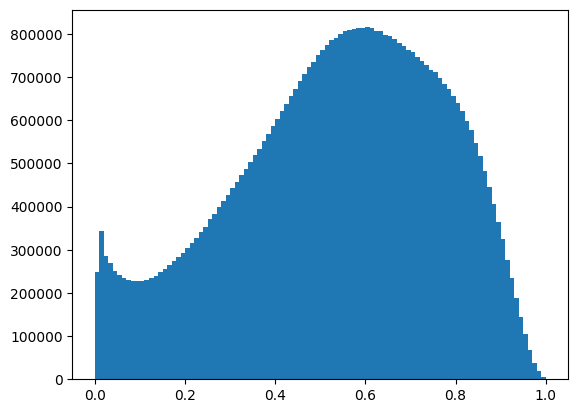

In [16]:
plt.hist(scores_minilm.reshape(-1), bins=100)

# old data new distribution

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

scores_minilm = np.load("scores/msmarco_raw/minilm_scores.npy")[:,:50]
scores_t5 = np.load("scores/msmarco_raw/t5_scores.npy")[:,:50]

# min-max normalization
scores_minilm = (scores_minilm - scores_minilm.min(axis=0)) / (scores_minilm.max(axis=0) - scores_minilm.min(axis=0))
scores_t5 = (scores_t5 - scores_t5.min(axis=0)) / (scores_t5.max(axis=0) - scores_t5.min(axis=0))

scores = scores_minilm + scores_t5
scores /= 2
scores = scores.astype(np.float32)

In [61]:
scores.mean(), scores.reshape(-1).var(), scores.reshape(-1).min(), scores.reshape(-1).max()

(np.float32(0.7090635),
 np.float32(0.018031739),
 np.float32(0.013519287),
 np.float32(0.9951172))

In [ ]:
with open("msmarco_scores.pkl", "rb") as f:
    target_scores = np.array(pickle.load(f))
print(target_scores.shape, target_scores.mean(), target_scores.var(), target_scores.min(), target_scores.max())
final_scores = (scores - scores.mean())*(target_scores.std()/scores.std()) + target_scores.mean()

((502822, 100),
 np.float64(0.8310783877590019),
 np.float64(28.38879802989393),
 np.float64(-11.544254302978516),
 np.float64(11.673728942871094))

In [73]:
import xopen
import orjson

with xopen.xopen("raw/q_ids.json") as f:
    q_ids = orjson.loads(f.read())

with xopen.xopen("raw/d_ids.json") as f:
    d_ids = orjson.loads(f.read())


In [94]:
num = 0
new_scores_dict = {}
final_scores_list = final_scores.tolist()
for i in range(len(q_ids)):
    q_id = int(q_ids[i])
    d_id = [int(x) for x in d_ids[i][:50]]

    flag = False
    for pos in accessor.qrels[q_id]:
        if pos not in d_id:
            num+=1
            flag = True
            break
    if flag:
        continue

    new_scores_dict[q_id] = {d_id[j]: final_scores_list[i][j] for j in range(len(d_id))}

import gzip
import pickle

with gzip.open("scores_dict_old_data.pkl.gz", "wb", compresslevel=1) as f:   # 1 更快，9 最省空间
    pickle.dump(new_scores_dict, f, protocol=pickle.HIGHEST_PROTOCOL)

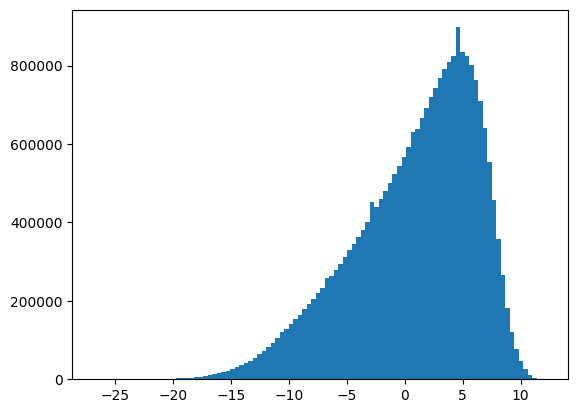

In [79]:
plt.hist(final_scores.reshape(-1), bins=100)
plt.show()

